In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import urllib.request

device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(42)
print("Using device:", device)

Using device: cuda


In [2]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text = urllib.request.urlopen(url).read().decode('utf-8')

print("Total characters:", len(text))
print(text[:200])

# Vocabulary: every unique character is a token
chars = sorted(list(set(text)))
vocab_size = len(chars)
print("Vocabulary size:", vocab_size)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join(itos[i] for i in l)

Total characters: 1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you
Vocabulary size: 65


In [3]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

block_size = 64    # context length (how many tokens the model sees)
batch_size = 64

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])          # input tokens
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])  # next tokens (targets)
    return x.to(device), y.to(device)

xb, yb = get_batch('train')
print("Input shape:", xb.shape, "| Target shape:", yb.shape)

Input shape: torch.Size([64, 64]) | Target shape: torch.Size([64, 64])


In [4]:
n_embd = 64      # embedding size
n_head = 4       # attention heads
n_layer = 2      # transformer blocks
dropout = 0.1

class SelfAttentionHead(nn.Module):
    """One head of causal self-attention"""
    def __init__(self, head_size):
        super().__init__()
        self.key   = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q, v = self.key(x), self.query(x), self.value(x)
        wei = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)       # attention scores
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # causal mask: no peeking at future
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        return wei @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([SelfAttentionHead(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """Transformer block: attention + feed-forward, with residuals and LayerNorm"""
    def __init__(self):
        super().__init__()
        self.sa = MultiHeadAttention(n_head, n_embd // n_head)
        self.ffwd = FeedForward()
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class TransformerLM(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block() for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx):
        B, T = idx.shape
        x = self.token_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        x = self.blocks(x)
        return self.head(self.ln_f(x))   # logits: (B, T, vocab_size)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits = self(idx_cond)[:, -1, :] / temperature
            probs = F.softmax(logits, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

model = TransformerLM().to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 112193


In [5]:
max_iters = 3000
eval_interval = 300
eval_iters = 50
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ['train', 'val']:
        losses = []
        for _ in range(eval_iters):
            x, y = get_batch(split)
            logits = model(x)
            losses.append(F.cross_entropy(logits.view(-1, vocab_size), y.view(-1)).item())
        out[split] = sum(losses) / len(losses)
    model.train()
    return out

train_losses, val_losses, steps = [], [], []

for it in range(max_iters + 1):
    if it % eval_interval == 0:
        l = estimate_loss()
        steps.append(it); train_losses.append(l['train']); val_losses.append(l['val'])
        print(f"Step {it:4d} | train loss {l['train']:.4f} | val loss {l['val']:.4f}")

    x, y = get_batch('train')
    logits = model(x)
    loss = F.cross_entropy(logits.view(-1, vocab_size), y.view(-1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

Step    0 | train loss 4.3317 | val loss 4.3318
Step  300 | train loss 2.3903 | val loss 2.4020
Step  600 | train loss 2.1563 | val loss 2.1828
Step  900 | train loss 2.0179 | val loss 2.0707
Step 1200 | train loss 1.9324 | val loss 2.0062
Step 1500 | train loss 1.8660 | val loss 1.9571
Step 1800 | train loss 1.8086 | val loss 1.9253
Step 2100 | train loss 1.7722 | val loss 1.8935
Step 2400 | train loss 1.7396 | val loss 1.8724
Step 2700 | train loss 1.7138 | val loss 1.8611
Step 3000 | train loss 1.6958 | val loss 1.8502


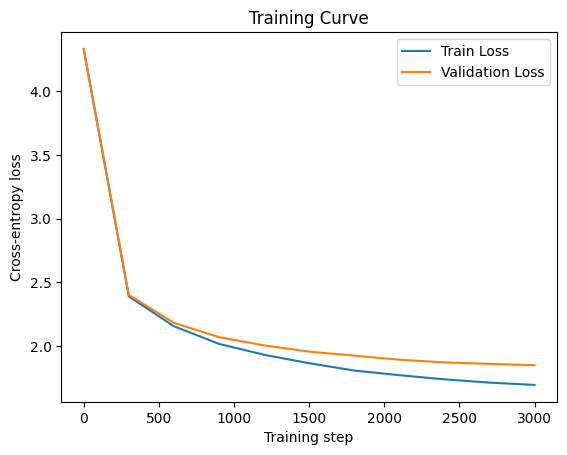

In [6]:
plt.plot(steps, train_losses, label='Train Loss')
plt.plot(steps, val_losses, label='Validation Loss')
plt.xlabel("Training step"); plt.ylabel("Cross-entropy loss")
plt.title("Training Curve"); plt.legend()
plt.show()

In [7]:
import math

model.eval()
total_loss, correct, top5_correct, total = 0, 0, 0, 0

with torch.no_grad():
    for _ in range(200):
        x, y = get_batch('val')
        logits = model(x)
        total_loss += F.cross_entropy(logits.view(-1, vocab_size), y.view(-1)).item()

        preds = logits.argmax(dim=-1)
        correct += (preds == y).sum().item()

        top5 = logits.topk(5, dim=-1).indices
        top5_correct += (top5 == y.unsqueeze(-1)).any(dim=-1).sum().item()
        total += y.numel()

avg_loss = total_loss / 200
print(f"Validation Loss     : {avg_loss:.4f}")
print(f"Perplexity          : {math.exp(avg_loss):.4f}")
print(f"Top-1 Accuracy      : {correct / total:.4f}")
print(f"Top-5 Accuracy      : {top5_correct / total:.4f}")
print(f"Random-guess baseline accuracy: {1 / vocab_size:.4f}")

Validation Loss     : 1.8425
Perplexity          : 6.3125
Top-1 Accuracy      : 0.4530
Top-5 Accuracy      : 0.7955
Random-guess baseline accuracy: 0.0154


In [8]:
start = torch.zeros((1, 1), dtype=torch.long, device=device)   # start token
generated = model.generate(start, max_new_tokens=500, temperature=0.8)
print(decode(generated[0].tolist()))


And lord, and my to countere with your for eer the to a fair,
Sir mare a love not it it bere our.

First Come, sir, so shall I then to they:
They to thou the reath to deeed with capplasenty to ding the banant you have
that didwiture take of thee, my do that is are to sore,
To dies lady cant an to actent to the his here
As fair too seel, my good the be him, hath is
Her our to word in this so, and the more are the
Are and vances much the
not of have thy would him daretuly me so may of flower
And b


In [9]:
prompt = "ROMEO:\n"
idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

with torch.no_grad():
    probs = F.softmax(model(idx)[:, -1, :], dim=-1)[0]

top = probs.topk(5)
print(f"Prompt: {repr(prompt)}")
for p, i in zip(top.values, top.indices):
    print(f"  next token {repr(itos[i.item()])}: {p.item():.3f}")

Prompt: 'ROMEO:\n'
  next token 'I': 0.156
  next token 'A': 0.114
  next token 'T': 0.104
  next token 'W': 0.096
  next token 'O': 0.071


In [10]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

block_size = 128   # longer context
batch_size = 64

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

In [11]:
n_embd = 256
n_head = 8
n_layer = 6
dropout = 0.2

class CausalSelfAttention(nn.Module):
    """Multi-head causal self-attention (all heads computed together)"""
    def __init__(self):
        super().__init__()
        self.qkv = nn.Linear(n_embd, 3 * n_embd, bias=False)
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(n_embd, dim=2)
        q = q.view(B, T, n_head, C // n_head).transpose(1, 2)
        k = k.view(B, T, n_head, C // n_head).transpose(1, 2)
        v = v.view(B, T, n_head, C // n_head).transpose(1, 2)
        out = F.scaled_dot_product_attention(
            q, k, v, is_causal=True,
            dropout_p=dropout if self.training else 0.0)
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.GELU(),
            nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.sa = CausalSelfAttention()
        self.ffwd = FeedForward()
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class TransformerLM(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[Block() for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init)

    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, idx):
        B, T = idx.shape
        x = self.token_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        x = self.blocks(self.drop(x))
        return self.head(self.ln_f(x))

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits = self(idx_cond)[:, -1, :] / temperature
            probs = F.softmax(logits, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

model = TransformerLM().to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 4800577


In [12]:
import math, copy

max_iters = 5000
eval_interval = 250
eval_iters = 50
max_lr, min_lr, warmup = 1e-3, 1e-4, 200

optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr,
                              betas=(0.9, 0.99), weight_decay=0.1)
use_amp = (device == 'cuda')
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def get_lr(it):
    if it < warmup:
        return max_lr * (it + 1) / warmup
    ratio = (it - warmup) / (max_iters - warmup)
    return min_lr + 0.5 * (1 + math.cos(math.pi * ratio)) * (max_lr - min_lr)

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ['train', 'val']:
        losses = []
        for _ in range(eval_iters):
            x, y = get_batch(split)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            losses.append(F.cross_entropy(logits.float().view(-1, vocab_size), y.view(-1)).item())
        out[split] = sum(losses) / len(losses)
    model.train()
    return out

train_losses, val_losses, steps = [], [], []
best_val, best_state = float('inf'), None

for it in range(max_iters + 1):
    for g in optimizer.param_groups:
        g['lr'] = get_lr(it)

    if it % eval_interval == 0:
        l = estimate_loss()
        steps.append(it); train_losses.append(l['train']); val_losses.append(l['val'])
        print(f"Step {it:4d} | train {l['train']:.4f} | val {l['val']:.4f}")
        if l['val'] < best_val:
            best_val = l['val']
            best_state = copy.deepcopy(model.state_dict())

    x, y = get_batch('train')
    with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
        logits = model(x)
    loss = F.cross_entropy(logits.float().view(-1, vocab_size), y.view(-1))

    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()

model.load_state_dict(best_state)   # restore the best checkpoint
print("Best validation loss:", round(best_val, 4))

Step    0 | train 4.1535 | val 4.1606
Step  250 | train 2.2179 | val 2.2496
Step  500 | train 1.7689 | val 1.9006
Step  750 | train 1.5662 | val 1.7400
Step 1000 | train 1.4543 | val 1.6468
Step 1250 | train 1.3812 | val 1.5861
Step 1500 | train 1.3424 | val 1.5529
Step 1750 | train 1.3006 | val 1.5230
Step 2000 | train 1.2690 | val 1.5179
Step 2250 | train 1.2439 | val 1.4972
Step 2500 | train 1.2192 | val 1.4942
Step 2750 | train 1.1915 | val 1.4688
Step 3000 | train 1.1730 | val 1.4606
Step 3250 | train 1.1573 | val 1.4661
Step 3500 | train 1.1413 | val 1.4615
Step 3750 | train 1.1174 | val 1.4507
Step 4000 | train 1.1075 | val 1.4598
Step 4250 | train 1.0993 | val 1.4617
Step 4500 | train 1.0893 | val 1.4595
Step 4750 | train 1.0802 | val 1.4574
Step 5000 | train 1.0772 | val 1.4668
Best validation loss: 1.4507


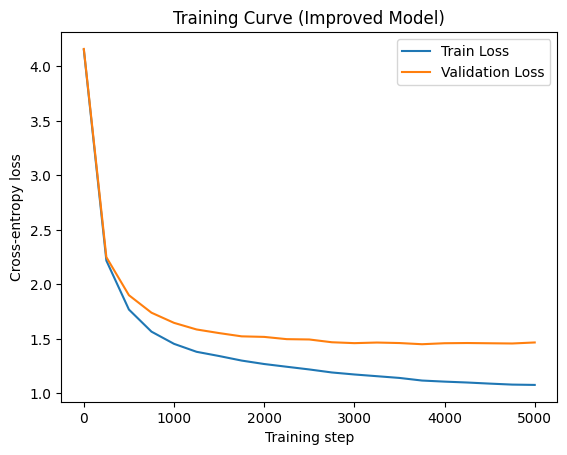

In [13]:
plt.plot(steps, train_losses, label='Train Loss')
plt.plot(steps, val_losses, label='Validation Loss')
plt.xlabel("Training step"); plt.ylabel("Cross-entropy loss")
plt.title("Training Curve (Improved Model)"); plt.legend()
plt.show()

In [14]:
model.eval()
total_loss, correct, top5_correct, total = 0, 0, 0, 0
n_batches = 200

with torch.no_grad():
    for _ in range(n_batches):
        x, y = get_batch('val')
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        logits = logits.float()
        total_loss += F.cross_entropy(logits.view(-1, vocab_size), y.view(-1)).item()
        correct += (logits.argmax(-1) == y).sum().item()
        top5_correct += (logits.topk(5, dim=-1).indices == y.unsqueeze(-1)).any(-1).sum().item()
        total += y.numel()

avg_loss = total_loss / n_batches
print(f"Validation Loss : {avg_loss:.4f}")
print(f"Perplexity      : {math.exp(avg_loss):.4f}")
print(f"Top-1 Accuracy  : {correct / total:.4f}")
print(f"Top-5 Accuracy  : {top5_correct / total:.4f}")
print(f"Random baseline : {1 / vocab_size:.4f}")

Validation Loss : 1.4567
Perplexity      : 4.2920
Top-1 Accuracy  : 0.5723
Top-5 Accuracy  : 0.8591
Random baseline : 0.0154


In [15]:
@torch.no_grad()
def generate_topk(model, idx, max_new_tokens, temperature=0.8, top_k=10):
    model.eval()
    for _ in range(max_new_tokens):
        logits = model(idx[:, -block_size:])[:, -1, :] / temperature
        v, _ = torch.topk(logits, top_k)
        logits[logits < v[:, [-1]]] = float('-inf')
        probs = F.softmax(logits, dim=-1)
        idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
    return idx

start = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(generate_topk(model, start, 600)[0].tolist()))


Who says and decreed, the fishion set his dead!

KING HENRY VI:
Have the comfort short and life?

QUEEN ELIZABETH:
My good lord, my lord.

KING RICHARD II:
So will I dislike a prisoner thing from her head.

HASTINGS:
Not on my gracious sister, but say 'side?

GLOUCESTER:
The gracious speedily lies: and therefore, for you make him.

HASTINGS:
The worst will be gone.

PAULINA:
I will have a friend to sleep in a suburfeit of trage.

LUCIO:
Marshal, marry, the man that will do look it by the death!
What shall I not think you there? take it with me,
To see the people's place of my head, if I could



In [16]:
prompt = "ROMEO:\n"
idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
model.eval()
with torch.no_grad():
    probs = F.softmax(model(idx)[:, -1, :], dim=-1)[0]

for p, i in zip(*probs.topk(5)):
    print(f"next token {repr(itos[i.item()])}: {p.item():.3f}")

next token 'W': 0.138
next token 'I': 0.113
next token 'T': 0.110
next token 'N': 0.093
next token 'A': 0.067


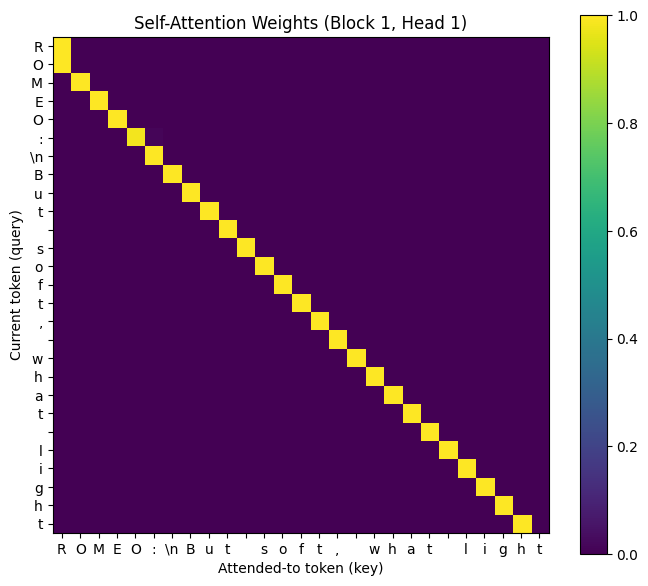

In [17]:
sentence = "ROMEO:\nBut soft, what light"
idx = torch.tensor([encode(sentence)], dtype=torch.long, device=device)
T = idx.shape[1]

model.eval()
with torch.no_grad():
    x = model.token_emb(idx) + model.pos_emb(torch.arange(T, device=device))
    sa = model.blocks[0].sa                       # first block
    h = model.blocks[0].ln1(x)
    q, k, _ = sa.qkv(h).split(n_embd, dim=2)
    hd = n_embd // n_head
    q = q.view(1, T, n_head, hd).transpose(1, 2)
    k = k.view(1, T, n_head, hd).transpose(1, 2)
    att = (q @ k.transpose(-2, -1)) / math.sqrt(hd)
    mask = torch.tril(torch.ones(T, T, device=device)).bool()
    att = att.masked_fill(~mask, float('-inf')).softmax(-1)[0, 0].cpu()  # head 0

labels = [c if c != '\n' else '\\n' for c in sentence]
plt.figure(figsize=(8, 7))
plt.imshow(att, cmap='viridis')
plt.xticks(range(T), labels); plt.yticks(range(T), labels)
plt.xlabel("Attended-to token (key)"); plt.ylabel("Current token (query)")
plt.title("Self-Attention Weights (Block 1, Head 1)")
plt.colorbar(); plt.show()

In [18]:
torch.save({'model_state': model.state_dict(),
            'stoi': stoi, 'itos': itos,
            'config': dict(n_embd=n_embd, n_head=n_head, n_layer=n_layer,
                           block_size=block_size, vocab_size=vocab_size)},
           'transformer_lm.pt')

from google.colab import files
files.download('transformer_lm.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
ckpt = torch.load('transformer_lm.pt', map_location=device)
model = TransformerLM().to(device)
model.load_state_dict(ckpt['model_state'])
model.eval()

TransformerLM(
  (token_emb): Embedding(65, 256)
  (pos_emb): Embedding(128, 256)
  (drop): Dropout(p=0.2, inplace=False)
  (blocks): Sequential(
    (0): Block(
      (sa): CausalSelfAttention(
        (qkv): Linear(in_features=256, out_features=768, bias=False)
        (proj): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
      )
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=256, out_features=1024, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=1024, out_features=256, bias=True)
          (3): Dropout(p=0.2, inplace=False)
        )
      )
      (ln1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (ln2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    )
    (1): Block(
      (sa): CausalSelfAttention(
        (qkv): Linear(in_features=256, out_features=768, bias=False)
        (proj): Linear(in_features=256, out_features=256,

In [20]:
url = "https://www.gutenberg.org/cache/epub/100/pg100.txt"   # Complete works of Shakespeare (~5 MB)
text = urllib.request.urlopen(url).read().decode('utf-8')